### Step 1: Connecting to BigQuery and Setting up Data Loading
In this step, we import the `pandas` library and set our Google Cloud project ID. We also create a helper function called `read_bq`. This function builds a SQL query to select all data from a specific table in our BigQuery dataset and loads it into a pandas DataFrame using the project ID.

In [3]:
import pandas as pd

project_id = "bqproj26"


def read_bq(table_name):
    query = f"SELECT * FROM `bqproj26.Final_Project_2026.{table_name}`"
    return pd.read_gbq(query, project_id=project_id)

### Step 2: Loading the Datasets
Here, we use our helper function `read_bq` to load three different tables from BigQuery: `geolocation`, `log_sales`, and `supermarkets_il`. Each dataset is saved into its own pandas DataFrame so we can analyze them later.

In [4]:
geolocation = read_bq("geolocation")
log_sales = read_bq("log_sales")
supermarkets_il = read_bq("supermarkets_il")

### Step 3: Checking Table Information
In this step, we put our three DataFrames into a dictionary to inspect them. We loop through each table to print its name, the total number of rows, and the data types of each column. This helps us understand the structure and size of our data.

In [5]:
tables = {
    "Geolocation": geolocation,
    "Log Sales": log_sales,
    "Supermarkets IL": supermarkets_il,
}

for name, df in tables.items():
    print(f"=== Table: {name} ===")
    print(f"Number of rows: {len(df)}")
    print("\nColumns and Data Types:")
    print(df.dtypes)
    print("-" * 40)

=== Table: Geolocation ===
Number of rows: 1308624

Columns and Data Types:
device_id                  object
lat                       float64
lon                       float64
timestamp     datetime64[us, UTC]
accuracy_m                float64
role                       object
area                       object
dtype: object
----------------------------------------
=== Table: Log Sales ===
Number of rows: 34589

Columns and Data Types:
sale_id                        object
timestamp         datetime64[us, UTC]
customer_id                    object
subtotal                      float64
tax                           float64
total                         float64
payment_method                 object
dwell_minutes                 float64
dtype: object
----------------------------------------
=== Table: Supermarkets IL ===
Number of rows: 2178

Columns and Data Types:
id        Int64
lat     float64
lon     float64
name     object
city     object
dtype: object
-----------------------------

### Step 4: Analyzing Daily Activity Patterns
This code block helps us understand when transmissions happen during the day. First, we convert the `timestamp` column to a standard datetime format. Then, we extract the hour and the date. Finally, we calculate the average number of transmissions for each hour of the day and display it as a bar chart.

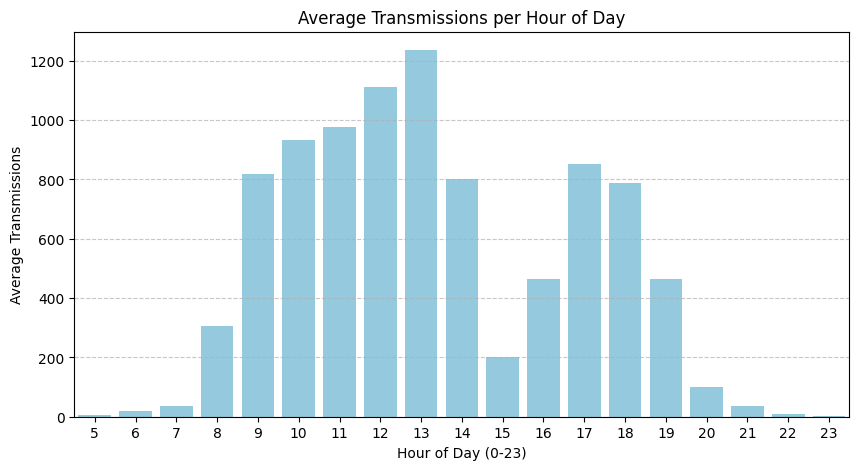

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

geolocation["timestamp"] = pd.to_datetime(geolocation["timestamp"])

geolocation["hour"] = geolocation["timestamp"].dt.hour
geolocation["date"] = geolocation["timestamp"].dt.date

hourly_counts = (
    geolocation.groupby(["date", "hour"]).size().reset_index(name="count")
)
avg_hourly_transmissions = (
    hourly_counts.groupby("hour")["count"].mean().reset_index()
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=avg_hourly_transmissions, x="hour", y="count", color="skyblue"
)
plt.title("Average Transmissions per Hour of Day")
plt.xlabel("Hour of Day (0-23)")
plt.ylabel("Average Transmissions")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

### Graph Interpretation:
Looking at the graph above, we can see the daily activity pattern:
* **Peak Hours (Busy Times):** The highest number of transmissions happens in the middle of the day, between **11:00 AM and 1:30 PM**. This is likely when the supermarket has the most customers.
* **Afternoon Drop:** There is a noticeable drop in activity around **3:00 PM**, which is usually a quieter time of day.
* **Evening Peak:** Activity goes up again around **5:00 PM to 6:00 PM** as people visit the supermarket after work.
* **Night/Early Morning:** There are almost no transmissions from **10:00 PM to 7:00 AM**, which shows the supermarket is closed.

### Step 5: Finding Low-Accuracy Transmissions
In this step, we check the quality of our GPS data. We count how many transmissions have an accuracy value greater than 30 meters (which means they are inaccurate). We also calculate what percentage of the total transmissions these inaccurate points represent.

In [7]:
outliers_count = (geolocation["accuracy_m"] > 30).sum()
total_transmissions = len(geolocation)
outliers_pct = (outliers_count / total_transmissions) * 100

print(f"Number of transmissions with accuracy > 30m: {outliers_count}")
print(f"Percentage of inaccurate transmissions: {outliers_pct:.2f}%")

Number of transmissions with accuracy > 30m: 415580
Percentage of inaccurate transmissions: 31.76%


### Step 6: Checking Customer Reception Quality
This step measures the transmission signal rate for our customers. We filter the data to keep only customers, calculate how long they stayed during each visit, and find out how many transmissions we actually received versus what we expected (one per minute). If the average transmission rate is 40% or higher, the system passes this quality requirement.

In [14]:
def check_reception_rate(df):
    """This function measures the reception rate of customers compared to how long they stayed.

    It returns True if the average reception rate is at least 40%.
    """
    # Filter the data to keep only customers
    customer_df = df[
        df["role"].isin(["repeat_customer", "one_time_customer"])
    ].copy()

    # Calculate total stay time in minutes for each customer during each visit
    stats = (
        customer_df.groupby(["device_id", "date"])
        .agg(
            start_time=("timestamp", "min"),
            end_time=("timestamp", "max"),
            actual_transmissions=("timestamp", "count"),
        )
        .reset_index()
    )

    # Calculate expected transmissions (we expect 1 transmission per minute)
    # Optimized: replaced .apply(lambda x: max(x, 1)) with vectorised .clip(lower=1)
    stats["expected_transmissions"] = (
        (stats["end_time"] - stats["start_time"]).dt.total_seconds() / 60
    ).clip(lower=1)

    # Calculate the actual reception rate percentage
    stats["reception_rate"] = (
        stats["actual_transmissions"] / stats["expected_transmissions"]
    ) * 100
    avg_rate = stats["reception_rate"].mean()

    print(f"Average Actual Reception Rate: {avg_rate:.2f}%")
    return avg_rate >= 40.0


# Run the quality check
meets_requirement = check_reception_rate(geolocation)
print(f"Meets 40% threshold requirement: {meets_requirement}")

Average Actual Reception Rate: 44.79%
Meets 40% threshold requirement: True
